# Plot the period distribution for different metallicities


## imports

In [1]:
from posydon.utils.common_functions import convert_metallicity_to_string, orbital_separation_from_period
from posydon.popsyn.distributions import PowerLawPeriod
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cmap import Colormap
import pickle
from pathlib import Path
from tqdm import tqdm
from scipy.stats import gaussian_kde
from helper_functions import calc_Teff, optical_depth_calculation

tol_vibrant = Colormap('tol:vibrant')(np.linspace(0, 1, 7))

COLORS = {0.0001: '#1f4e79',
           0.001: '#2e75b6',
            0.01: '#5ba3d0', 
             0.1: '#f4a261',
             0.2: '#e76f51',
            0.45: '#c0392b', 
             1.0: '#8e1a0e',
             2.0: '#5c0a0a'
             }

## Load POSYDON data

In [2]:
def load_metallicity(metallicity, data_folder):
    """Load and process WR phase data for a single metallicity.

    Returns a dict of arrays ready for analysis.
    """
    met_str = convert_metallicity_to_string(metallicity)
    file_path = data_folder / f'WR_phases_Z{met_str}_Zsun.pkl'
    with open(file_path, 'rb') as f:
        data = pickle.load(f)

    S1_WR_data = data['S1_WR_data']
    S2_WR_data = data['S2_WR_data']

    s1 = pd.concat(S1_WR_data.values(), keys=S1_WR_data.keys())
    s2 = pd.concat(S2_WR_data.values(), keys=S2_WR_data.keys())

    s1_Teff = 10**calc_Teff(s1['S1_log_L'], s1['S1_log_R'])
    s1_sep  = orbital_separation_from_period(s1['orbital_period'].values,
                                              s1['S1_mass'].values,
                                              s1['S2_mass'].values)
    s2_Teff = 10**calc_Teff(s2['S2_log_L'], s2['S2_log_R'])
    s2_sep  = orbital_separation_from_period(s2['orbital_period'].values,
                                              s2['S2_mass'].values,
                                              s2['S1_mass'].values)
    print(met_str)
    return {
        'time':             np.concatenate([s1['time'].values,               s2['time'].values]),
        'weight':           np.concatenate([s1['weight'].values,             s2['weight'].values]),
        'state':            np.concatenate([s1['state'].values,              s2['state'].values]),
        'key':              np.concatenate([s1.index.get_level_values(0),    s2.index.get_level_values(0)]),
        'star':             np.array(['S1'] * len(s1) + ['S2'] * len(s2)),
        'period':           np.concatenate([s1['orbital_period'].values,     s2['orbital_period'].values]),
        'separation':       np.concatenate([s1_sep,                          s2_sep]),
        'Teff':             np.concatenate([s1_Teff.values,                  s2_Teff.values]),
        'L':                np.concatenate([10**s1['S1_log_L'].values,       10**s2['S2_log_L'].values]),
        'optical_depth':    np.concatenate([s1['optical_depth'].values,      s2['optical_depth'].values]),
        'surface_H':        np.concatenate([s1['S1_surface_h1'].values,      s2['S2_surface_h1'].values]),
        'surface_He':       np.concatenate([s1['S1_surface_he4'].values,     s2['S2_surface_he4'].values]),
        'mass':             np.concatenate([s1['S1_mass'].values,            s2['S2_mass'].values]),
        'mass_companion':   np.concatenate([s1['S2_mass'].values,            s2['S1_mass'].values]),
        'radius':           np.concatenate([10**s1['S1_log_R'].values,       10**s2['S2_log_R'].values]),
        'Mdot':             np.concatenate([10**s1['S1_lg_mdot'].values,     10**s2['S2_lg_mdot'].values]),
        'companion':        np.concatenate([s1['S2_state'].values,           s2['S1_state'].values]),
        'S1_state':         np.concatenate([s1['S1_state'].values,           s2['S2_state'].values]),
        'model_weight':     np.concatenate([s1['model_weight'].values,       s2['model_weight'].values]),
    }


data_folder = Path('/Users/max/Documents/projects/WR_population/data/optical_depth/')
metallicities = [0.01, 0.1, 0.2, 0.45, 1.0]#[0.01, 0.1, 0.2, 0.45, 1.0]  # in units of Zsun

WR_data = {Z: load_metallicity(Z, data_folder) for Z in metallicities}

1e-02
1e-01
2e-01
4.5e-01
1e+00


In [3]:

def classify_WR(d):
    """Return WNL, WNE, WC boolean masks for a data dict from load_metallicity."""
    WNL = (
        (d['surface_H'] > 0.05) & (d['surface_H'] <= 0.5)
        & (d['optical_depth'] > 1.5)
        & ~pd.Series(d['S1_state']).str.contains('H_burning', na=False).values
    )
    WNE = (d['surface_H'] <= 0.05) & (d['surface_He'] >= 0.7) & (d['optical_depth'] > 1.5)
    WC  = (d['surface_H'] <= 0.05) & (d['surface_He'] <  0.7) & (d['optical_depth'] > 1.5)
    return WNL, WNE, WC


def make_binary_mask(d):
    """Return mask for detached/RLO/contact binaries."""
    s = d['state']
    return (s == 'detached') | (s == 'RLO1') | (s == 'contact') | (s == 'RLO2')

def classify_WR_MS(d):
    WNL = (
        (d['surface_H'] > 0.05) & (d['surface_H'] <= 0.5)
        & (d['optical_depth'] > 1.5)
    )
    WNE = (d['surface_H'] <= 0.05) & (d['surface_He'] >= 0.7) & (d['optical_depth'] > 1.5)
    WC  = (d['surface_H'] <= 0.05) & (d['surface_He'] <  0.7) & (d['optical_depth'] > 1.5)
    return WNL, WNE, WC

def classify_WR_optical_depth(d):
    """Return WNL, WNE, WC boolean masks for a data dict from load_metallicity."""
    WNL = (
        (d['surface_H'] > 0.05) & (d['surface_H'] <= 0.5)
        & (d['optical_depth'] > 0.5)
        & ~pd.Series(d['S1_state']).str.contains('H_burning', na=False).values
    )
    WNE = (d['surface_H'] <= 0.05) & (d['surface_He'] >= 0.7) & (d['optical_depth'] > 0.5)
    WC  = (d['surface_H'] <= 0.05) & (d['surface_He'] <  0.7) & (d['optical_depth'] > 0.5)
    return WNL, WNE, WC



In [4]:
# Example: compute WR type fractions for each metallicity
for Z, d in WR_data.items():
    WNL, WNE, WC = classify_WR(d)
    bm = make_binary_mask(d)
    w = d['weight']
    total = np.sum(w[bm & (WNL | WNE | WC)])
    WNL_fraction = np.sum(w[bm & WNL]) / total
    WNE_fraction = np.sum(w[bm & WNE]) / total
    WC_fraction  = np.sum(w[bm & WC])  / total
    print(f"Z = {Z} Zsun  ->  WNL: {WNL_fraction*100:.0f}%  WNE: {WNE_fraction*100:.0f}%  WC: {WC_fraction*100:.0f}%")


Z = 0.01 Zsun  ->  WNL: 65%  WNE: 24%  WC: 11%
Z = 0.1 Zsun  ->  WNL: 57%  WNE: 34%  WC: 8%
Z = 0.2 Zsun  ->  WNL: 45%  WNE: 45%  WC: 9%
Z = 0.45 Zsun  ->  WNL: 28%  WNE: 55%  WC: 17%
Z = 1.0 Zsun  ->  WNL: 16%  WNE: 55%  WC: 29%


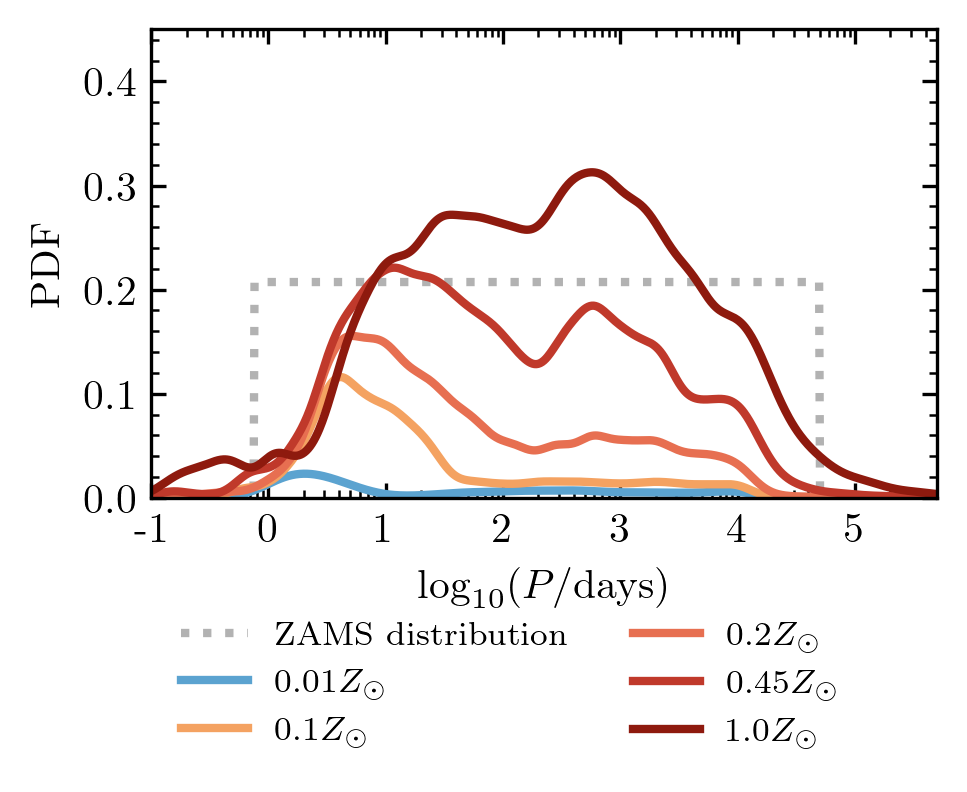

In [5]:

LOG_P_MIN = -1
LOG_P_MAX = 7

fig, ax = plt.subplots(1, 1, figsize=(3.38, 2.535*0.8))
metallicity_labels = ['0.01', '0.1', '0.2', '0.45', '1.0']

PDF_logP = PowerLawPeriod(p_min=0.75, p_max=50000.0, slope=0.0)
x_eval = np.linspace(LOG_P_MIN, LOG_P_MAX, 1000)

flatP = PDF_logP.pdf(10**x_eval)
ax.plot(10**x_eval, flatP, ':',
        color='black', linewidth=2, alpha=0.3, 
         label=f'ZAMS distribution')

mask_1Zsun = make_binary_mask(WR_data[1.0])
WNL_1Zsun, WNE_1Zsun, WC_1Zsun = classify_WR(WR_data[1.0])
weights_1Zsun = WR_data[1.0]['weight'] * WR_data[1.0]['model_weight']
Zsun_weight_total = np.sum(weights_1Zsun[mask_1Zsun & (WNL_1Zsun | WNE_1Zsun | WC_1Zsun)])

for met in metallicities:
    weights = WR_data[met]['weight'] * WR_data[met]['model_weight']
    period_array = WR_data[met]['period']
    mask = make_binary_mask(WR_data[met])
    WNL, WNE, WC = classify_WR(WR_data[met])
    kde = gaussian_kde(np.log10(period_array[mask & (WNL | WNE | WC)]), weights=weights[mask & (WNL | WNE | WC)], bw_method=0.1)
    kde_eval = kde(x_eval)
    rescale =  np.sum(weights[mask & (WNL | WNE | WC)]) / Zsun_weight_total
    ax.plot(10**x_eval, kde_eval*rescale, color=COLORS[met], label=metallicity_labels[metallicities.index(met)]+'$Z_\odot$', linewidth=2)


# Housekeeping for layout
ax.set_xlabel('$\log_{10}(P/\mathrm{days})$')
ax.set_xscale('log')
ax.set_xlim(1e-1, 5e5)
ax.set_xticks([0.1, 1, 10, 100, 1000, 10000, 100000])
ax.set_xticklabels(['-1', '0', '1', '2', '3', '4', '5'])
ax.set_ylim(0, 0.45)
ax.grid(False)
#ax.grid(True, which='major', ls='--', alpha=0.3)    
ax.set_ylabel('PDF')

ax.legend(bbox_to_anchor=(0.0, -0.2), loc='upper left', ncol=2)

figure_folder = Path('/Users/max/Documents/projects/WR_population/figure_scripts/figures/')

plt.savefig(figure_folder / 'pdf' / 'metallicity_dependence.pdf', bbox_inches='tight')
plt.savefig(figure_folder / 'png' / 'metallicity_dependence.png', bbox_inches='tight', dpi=300)
plt.show()

# Different period distribution

In [6]:
from posydon.popsyn.distributions import Sana12Period


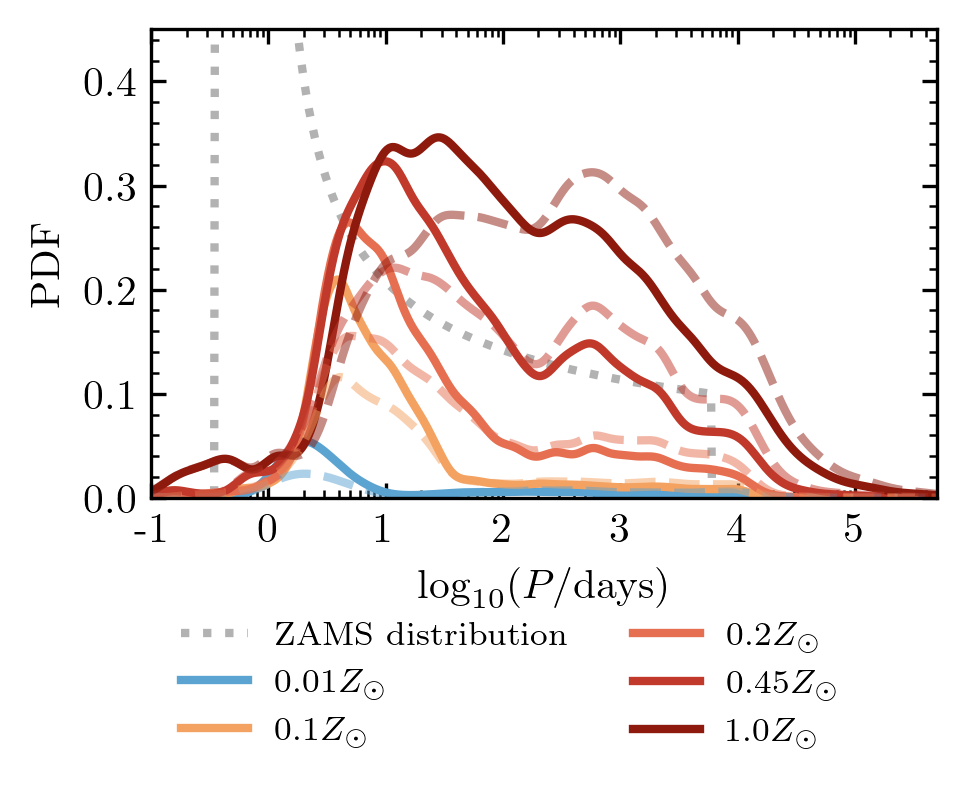

In [10]:

LOG_P_MIN = -1
LOG_P_MAX = 7

fig, ax = plt.subplots(1, 1, figsize=(3.38, 2.535*0.8))
metallicity_labels = ['0.01', '0.1', '0.2', '0.45', '1.0']
PDF_logP = Sana12Period()

x_eval = np.linspace(LOG_P_MIN, LOG_P_MAX, 1000)
flatP = PDF_logP.pdf(10**x_eval, m1=20)

ax.plot(10**x_eval, flatP, ':',
        color='black', linewidth=2, alpha=0.3, 
         label=f'ZAMS distribution')

mask_1Zsun = make_binary_mask(WR_data[1.0])
WNL_1Zsun, WNE_1Zsun, WC_1Zsun = classify_WR(WR_data[1.0])
weights_1Zsun = np.where(np.isclose(WR_data[1.0]['model_weight'],0.0), 0, WR_data[1.0]['weight'])


#weights_1Zsun = WR_data[1.0]['weight'] #* WR_data[1.0]['model_weight']
Zsun_weight_total = np.sum(weights_1Zsun[mask_1Zsun & (WNL_1Zsun | WNE_1Zsun | WC_1Zsun)])

for met in metallicities:
    weights = np.where(np.isclose(WR_data[met]['model_weight'], 0.0), 0, WR_data[met]['weight'])
    period_array = WR_data[met]['period']
    mask = make_binary_mask(WR_data[met])
    WNL, WNE, WC = classify_WR(WR_data[met])
    kde = gaussian_kde(np.log10(period_array[mask & (WNL | WNE | WC)]), weights=weights[mask & (WNL | WNE | WC)], bw_method=0.1)
    kde_eval = kde(x_eval)
    rescale =  np.sum(weights[mask & (WNL | WNE | WC)]) / Zsun_weight_total
    ax.plot(10**x_eval, kde_eval*rescale, color=COLORS[met], label=metallicity_labels[metallicities.index(met)]+'$Z_\odot$', linewidth=2)



mask_1Zsun = make_binary_mask(WR_data[1.0])
WNL_1Zsun, WNE_1Zsun, WC_1Zsun = classify_WR(WR_data[1.0])
weights_1Zsun = WR_data[1.0]['weight'] * WR_data[1.0]['model_weight']
Zsun_weight_total = np.sum(weights_1Zsun[mask_1Zsun & (WNL_1Zsun | WNE_1Zsun | WC_1Zsun)])

for met in metallicities:
    weights = WR_data[met]['weight'] * WR_data[met]['model_weight']
    period_array = WR_data[met]['period']
    mask = make_binary_mask(WR_data[met])
    WNL, WNE, WC = classify_WR(WR_data[met])
    kde = gaussian_kde(np.log10(period_array[mask & (WNL | WNE | WC)]), weights=weights[mask & (WNL | WNE | WC)], bw_method=0.1)
    kde_eval = kde(x_eval)
    rescale =  np.sum(weights[mask & (WNL | WNE | WC)]) / Zsun_weight_total
    ax.plot(10**x_eval, kde_eval*rescale, color=COLORS[met], ls='--', alpha=0.5, linewidth=2)



# Housekeeping for layout
ax.set_xlabel('$\log_{10}(P/\mathrm{days})$')
ax.set_xscale('log')
ax.set_xlim(1e-1, 5e5)
ax.set_xticks([0.1, 1, 10, 100, 1000, 10000, 100000])
ax.set_xticklabels(['-1', '0', '1', '2', '3', '4', '5'])
ax.set_ylim(0, 0.45)
ax.grid(False)
#ax.grid(True, which='major', ls='--', alpha=0.3)    
ax.set_ylabel('PDF')

ax.legend(bbox_to_anchor=(0.0, -0.2), loc='upper left', ncol=2)

figure_folder = Path('/Users/max/Documents/projects/WR_population/figure_scripts/figures/')

plt.savefig(figure_folder / 'pdf' / 'metallicity_dependence_Sana12.pdf', bbox_inches='tight')
plt.savefig(figure_folder / 'png' / 'metallicity_dependence_Sana12.png', bbox_inches='tight', dpi=300)
plt.show()

# Tau=0.5 boundary

Z = 0.01 Zsun
number of models: 418173
unique models: 44899
weighted: 69.47378204062714
Z = 0.1 Zsun
number of models: 924870
unique models: 79107
weighted: 250.05421043713116
Z = 0.2 Zsun
number of models: 1588203
unique models: 89559
weighted: 446.682115423397
Z = 0.45 Zsun
number of models: 2411692
unique models: 88283
weighted: 756.571946133878
Z = 1.0 Zsun
number of models: 3266623
unique models: 92006
weighted: 1126.5747146657916


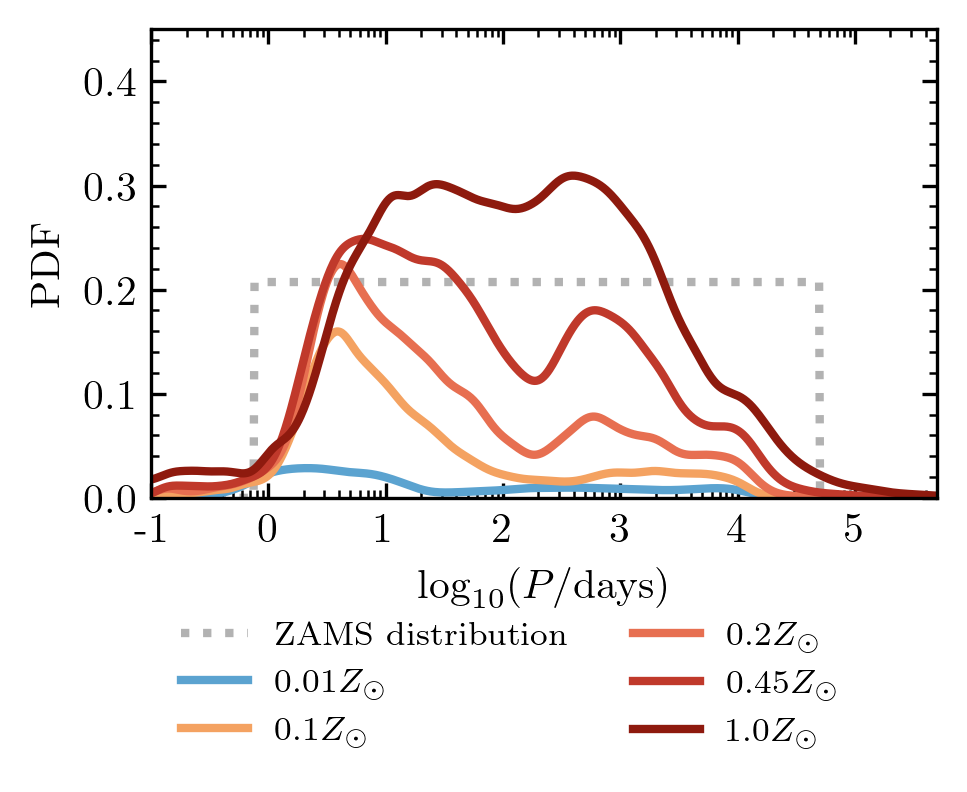

In [ ]:

LOG_P_MIN = -1
LOG_P_MAX = 7

fig, ax = plt.subplots(1, 1, figsize=(3.38, 2.535*0.8))
metallicity_labels = ['0.01', '0.1', '0.2', '0.45', '1.0']

PDF_logP = PowerLawPeriod(p_min=0.75, p_max=50000.0, slope=0.0)
x_eval = np.linspace(LOG_P_MIN, LOG_P_MAX, 1000)

flatP = PDF_logP.pdf(10**x_eval)
ax.plot(10**x_eval, flatP, ':',
        color='black', linewidth=2, alpha=0.3, 
         label=f'ZAMS distribution')

mask_1Zsun = make_binary_mask(WR_data[1.0])
WNL_1Zsun, WNE_1Zsun, WC_1Zsun = classify_WR_optical_depth(WR_data[1.0])
weights_1Zsun = WR_data[1.0]['weight'] * WR_data[1.0]['model_weight']
Zsun_weight_total = np.sum(weights_1Zsun[mask_1Zsun & (WNL_1Zsun | WNE_1Zsun | WC_1Zsun)])

for met in metallicities:
    weights = WR_data[met]['weight'] * WR_data[met]['model_weight']
    period_array = WR_data[met]['period']
    mask = make_binary_mask(WR_data[met])
    WNL, WNE, WC = classify_WR_optical_depth(WR_data[met])
    kde = gaussian_kde(np.log10(period_array[mask & (WNL | WNE | WC)]), weights=weights[mask & (WNL | WNE | WC)], bw_method=0.1)
    kde_eval = kde(x_eval)
    rescale =  np.sum(weights[mask & (WNL | WNE | WC)]) / Zsun_weight_total
    ax.plot(10**x_eval, kde_eval*rescale, color=COLORS[met], label=metallicity_labels[metallicities.index(met)]+'$Z_\odot$', linewidth=2)
    print(f"Z = {met} Zsun")
    print("number of models:", np.sum(mask & (WNL | WNE | WC)))
    print('unique models:', len(np.unique(WR_data[met]['key'][mask & (WNL | WNE | WC)])))
    print('weighted:',np.sum(weights[mask & (WNL | WNE | WC)]))


# Housekeeping for layout
ax.set_xlabel('$\log_{10}(P/\mathrm{days})$')
ax.set_xscale('log')
ax.set_xlim(1e-1, 5e5)
ax.set_xticks([0.1, 1, 10, 100, 1000, 10000, 100000])
ax.set_xticklabels(['-1', '0', '1', '2', '3', '4', '5'])
ax.set_ylim(0, 0.45)
ax.grid(False)
#ax.grid(True, which='major', ls='--', alpha=0.3)    
ax.set_ylabel('PDF')

ax.legend(bbox_to_anchor=(0.0, -0.2), loc='upper left', ncol=2)

figure_folder = Path('/Users/max/Documents/projects/WR_population/figure_scripts/figures/')

plt.savefig(figure_folder / 'pdf' / 'metallicity_dependence_lower_optical_depth.pdf', bbox_inches='tight')
plt.savefig(figure_folder / 'png' / 'metallicity_dependence_lower_optical_depth.png', bbox_inches='tight', dpi=300)
plt.show()

# Mass distributions

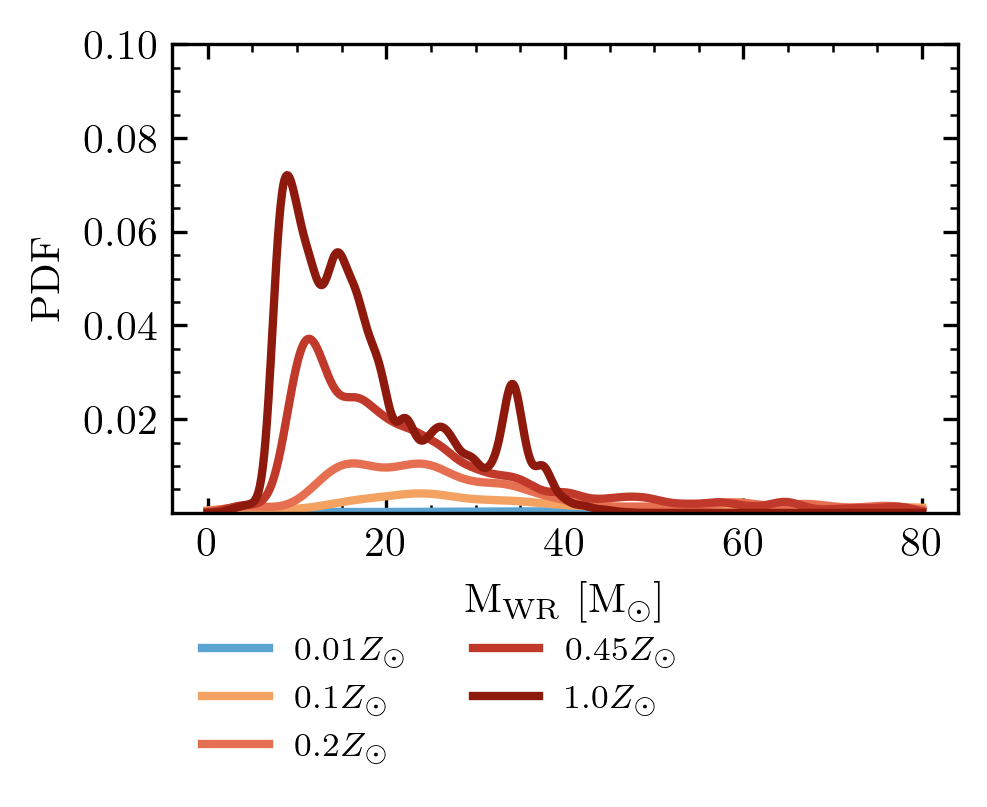

In [9]:
fig, ax = plt.subplots(1, 1, figsize=(3.38, 2.535*0.8))
metallicity_labels = ['0.01', '0.1', '0.2', '0.45', '1.0']

#PDF_logP = PowerLawPeriod(p_min=0.75, p_max=6000.0, slope=0.0)
#x_eval = np.linspace(LOG_P_MIN, LOG_P_MAX, 1000)

#flatP = PDF_logP.pdf(10**x_eval)
#ax.plot(10**x_eval, flatP, ':',
#        color='black', linewidth=2, alpha=0.3, 
#         label=f'ZAMS distribution')

x_eval = np.linspace(0, 80, 1000)

mask_1Zsun = make_binary_mask(WR_data[1.0])
WNL_1Zsun, WNE_1Zsun, WC_1Zsun = classify_WR(WR_data[1.0])
weights_1Zsun = WR_data[1.0]['weight'] * WR_data[1.0]['model_weight']
Zsun_weight_total = np.sum(weights_1Zsun[mask_1Zsun & (WNL_1Zsun | WNE_1Zsun | WC_1Zsun)])

for met in metallicities:
    weights = WR_data[met]['weight'] * WR_data[met]['model_weight']
    mass_array = WR_data[met]['mass']
    mask = make_binary_mask(WR_data[met])
    WNL, WNE, WC = classify_WR(WR_data[met])
    kde = gaussian_kde(mass_array[mask & (WNL | WNE | WC)], weights=weights[mask & (WNL | WNE | WC)])
    kde_eval = kde(x_eval)
    rescale =  np.sum(weights[mask & (WNL | WNE | WC)]) / Zsun_weight_total
    ax.plot(x_eval, kde_eval*rescale, color=COLORS[met], label=metallicity_labels[metallicities.index(met)]+'$Z_\odot$', linewidth=2)


# Housekeeping for layout
ax.set_xlabel('M$_\mathrm{WR}$ [$\mathrm{M}_\odot]$')
#ax.set_xscale('log')
#ax.set_xlim(1e-1, 5e5)
#ax.set_xticks([0.1, 1, 10, 100, 1000, 10000, 100000])
#ax.set_xticklabels(['-1', '0', '1', '2', '3', '4', '5'])
#ax.set_ylim(0, 0.45)
ax.grid(False)
#ax.grid(True, which='major', ls='--', alpha=0.3)    
ax.set_ylabel('PDF')
#ax.set_yscale('log')
ax.set_ylim(1e-5,0.1)
ax.legend(bbox_to_anchor=(0.0, -0.2), loc='upper left', ncol=2)

figure_folder = Path('/Users/max/Documents/projects/WR_population/figure_scripts/figures/')

#plt.savefig(figure_folder / 'pdf' / 'metallicity_dependence.pdf', bbox_inches='tight')
#plt.savefig(figure_folder / 'png' / 'metallicity_dependence.png', bbox_inches='tight', dpi=300)
plt.show()